In [ ]:
import pandas as pd
import numpy as np

# 1. On charge les 3 fichiers produits par la partie données
prix   = pd.read_csv("data/final/prix_ajustes.csv", parse_dates=["date"])
tun    = pd.read_csv("data/final/tunindex.csv", parse_dates=["date"])
titres = pd.read_csv("data/final/titres_retenus.csv")

# 2. On regarde leur forme et leurs colonnes
print("Prix :", prix.shape, "| colonnes :", prix.columns.tolist())
print("Nombre de titres :", prix["ticker"].nunique())
print("Période :", prix["date"].min().date(), "→", prix["date"].max().date())
print("Tunindex :", len(tun), "séances")
print("Séances neutralisées :", int(prix["seance_neutralisee"].sum()))

# 3. On affiche les 5 premières lignes de BIAT
prix[prix["ticker"] == "BIAT"].head()

In [1]:
import pandas as pd
import numpy as np

# 1. On charge les 3 fichiers produits par la partie données
prix   = pd.read_csv("data/final/prix_ajustes.csv", parse_dates=["date"])
tun    = pd.read_csv("data/final/tunindex.csv", parse_dates=["date"])
titres = pd.read_csv("data/final/titres_retenus.csv")

# 2. On regarde leur forme et leurs colonnes
print("Prix :", prix.shape, "| colonnes :", prix.columns.tolist())
print("Nombre de titres :", prix["ticker"].nunique())
print("Période :", prix["date"].min().date(), "→", prix["date"].max().date())
print("Tunindex :", len(tun), "séances")
print("Séances neutralisées :", int(prix["seance_neutralisee"].sum()))

# 3. On affiche les 5 premières lignes de BIAT
prix[prix["ticker"] == "BIAT"].head()

Prix : (48604, 6) | colonnes : ['date', 'ticker', 'close_brut', 'close_ajuste', 'volume', 'seance_neutralisee']
Nombre de titres : 56
Période : 2023-01-02 → 2026-11-18
Tunindex : 961 séances
Séances neutralisées : 3


,date,ticker,close_brut,close_ajuste,volume,seance_neutralisee
7662,2023-01-02,BIAT,89.00,62.186523,2691,0
7663,2023-01-03,BIAT,89.40,62.466013,4504,0
7664,2023-01-04,BIAT,89.35,62.431077,3479,0
7665,2023-01-05,BIAT,89.40,62.466013,1338,0
7666,2023-01-06,BIAT,89.60,62.605758,1545,0


In [2]:
# 1. Tableau "large" : une ligne par date, une colonne par titre
P = prix.pivot(index="date", columns="ticker", values="close_ajuste")
P = P.reindex(tun["date"])          # on aligne sur le calendrier du Tunindex (961 séances)
print("Tableau des prix :", P.shape)
print("Cases vides avant remplissage :", int(P.isna().sum().sum()))

# 2. Jour sans échange = dernier cours connu (option A)
P = P.ffill()

# 3. Rendement logarithmique : r(t) = ln( P(t) / P(t-1) )
R = np.log(P / P.shift(1))

# 4. Les 3 séances neutralisées : on met leur rendement à 0
neut = prix[prix["seance_neutralisee"] == 1][["date", "ticker"]]
for d, t in neut.itertuples(index=False):
    print("Neutralisé :", t, d.date(), "rendement d'origine =", round(R.loc[d, t], 4))
    R.loc[d, t] = 0.0

R = R.iloc[1:]                       # la 1re séance n'a pas de veille

# 5. Rendements du Tunindex (même calcul)
M = np.log(tun.set_index("date")["close"]).diff().iloc[1:]

print("Rendements :", R.shape, "| Tunindex :", M.shape)
print("Cases vides restantes :", int(R.isna().sum().sum()))
R["BIAT"].describe()

Tableau des prix : (961, 56)
Cases vides avant remplissage : 5582
Neutralisé : CELL 2023-04-18 rendement d'origine = -0.3528
Neutralisé : CIL 2023-05-16 rendement d'origine = -0.3327
Neutralisé : TJARI 2025-04-30 rendement d'origine = -0.1412
Rendements : (960, 56) | Tunindex : (960,)
Cases vides restantes : 21


count    960.000000
mean       0.001093
std        0.010084
min       -0.059719
25%       -0.002594
50%        0.000000
75%        0.004517
max        0.058269
Name: BIAT, dtype: float64

In [3]:
# 1. Quels titres ont des cases vides, et combien ?
vides = R.isna().sum()
print(vides[vides > 0])

# 2. On commence au premier jour où les 56 titres ont tous un rendement
debut = R.dropna().index.min()
R = R.loc[debut:]
M = M.loc[debut:]
print("Début de l'étude :", debut.date(), "| séances :", len(R))
print("Cases vides restantes :", int(R.isna().sum().sum()))

# 3. Part des jours à rendement nul (indicateur d'illiquidité)
print((R == 0).mean().sort_values(ascending=False).head(8).round(2))

# 4. Sauvegarde pour le jour 2
import os
os.makedirs("resultats", exist_ok=True)
R.to_csv("resultats/rendements_log.csv")
M.to_frame("TUNINDEX").to_csv("resultats/tunindex_rendements.csv")
print("Fichiers enregistrés dans resultats/")

ticker
AL       2
CELL    13
SCB      3
TRE      3
dtype: int64
Début de l'étude : 2023-01-20 | séances : 947
Cases vides restantes : 0
ticker
TAIR     0.61
WIFAK    0.61
SCB      0.59
AL       0.54
SOMOC    0.50
MNP      0.50
BTE      0.49
STAR     0.48
dtype: float64
Fichiers enregistrés dans resultats/


In [4]:
from scipy import stats
JOURS = 252
n = len(R)                       # nombre de rendements (947)
mu = R.mean()                    # moyenne journalière de chaque titre
s  = R.std(ddof=1)               # écart-type journalier (on divise par n-1)

F = pd.DataFrame(index=R.columns)
# 1-2. Rendement et volatilité annualisés
F["rendement_annualise"]   = mu * JOURS
F["volatilite_annualisee"] = s * np.sqrt(JOURS)

# 3-4. Skewness et kurtosis (mêmes formules corrigées que dans Excel)
z = (R - mu) / s                 # rendements centrés-réduits
F["skewness"] = n / ((n-1)*(n-2)) * (z**3).sum()
F["kurtosis"] = n*(n+1)/((n-1)*(n-2)*(n-3)) * (z**4).sum() - 3*(n-1)**2/((n-2)*(n-3))

# 5-6. VaR et CVaR historiques à 95 % (en perte positive, sur 1 jour)
q = R.quantile(0.05)             # le rendement des 5 % pires jours
F["VaR_95"]  = -q
F["CVaR_95"] = -R[R.le(q)].mean()

# 7. Bêta = Cov(titre, marché) / Var(marché)
F["beta"] = R.apply(lambda col: np.cov(col, M, ddof=1)[0, 1]) / M.var(ddof=1)

# Vérification avec scipy (doit afficher True deux fois)
print(np.allclose(F["skewness"], stats.skew(R, bias=False)),
      np.allclose(F["kurtosis"], stats.kurtosis(R, bias=False)))

F.to_csv("resultats/features.csv")
F.round(4).loc[["BIAT", "SFBT", "TJARI", "TAIR"]]

True True


,rendement_annualise,volatilite_annualisee,skewness,kurtosis,VaR_95,CVaR_95,beta
ticker,,,,,,,
BIAT,0.2540,0.1591,0.4722,6.2667,0.0121,0.0217,1.3745
SFBT,0.0958,0.1679,0.9681,4.9318,0.0144,0.0213,0.8121
TJARI,0.2881,0.1985,1.0986,10.2015,0.0160,0.0256,1.4945
TAIR,-0.0704,0.3007,-0.1104,2.0820,0.0290,0.0376,-0.2107


      rendement_annualise  volatilite_annualisee  skewness  kurtosis  VaR_95  \
mean                0.183                  0.270     0.477     7.289   0.025   
min                -0.249                  0.159    -1.806     1.634   0.011   
50%                 0.218                  0.250     0.489     4.199   0.022   
max                 0.554                  0.503     2.142    37.033   0.045   

      CVaR_95   beta  
mean    0.037  0.513  
min     0.018 -0.211  
50%     0.035  0.479  
max     0.075  1.495  


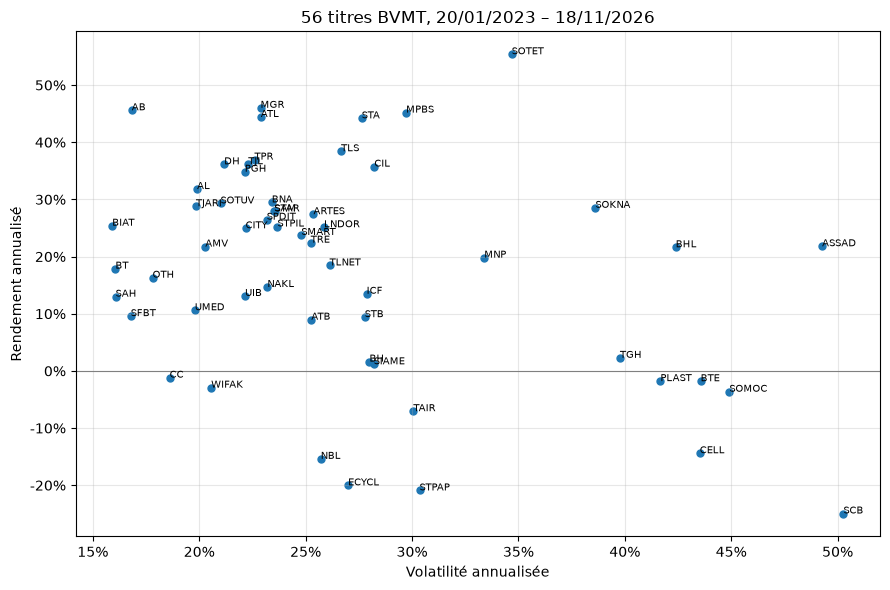


Pearson
                        rendement_annualise  volatilite_annualisee  skewness  \
rendement_annualise                   1.00                  -0.36      0.54   
volatilite_annualisee                -0.36                   1.00     -0.39   
skewness                              0.54                  -0.39      1.00   
kurtosis                             -0.27                   0.33      0.11   
VaR_95                               -0.40                   0.95     -0.48   
CVaR_95                              -0.47                   0.97     -0.51   
beta                                  0.41                  -0.49      0.37   

                       kurtosis  VaR_95  CVaR_95  beta  
rendement_annualise       -0.27   -0.40    -0.47  0.41  
volatilite_annualisee      0.33    0.95     0.97 -0.49  
skewness                   0.11   -0.48    -0.51  0.37  
kurtosis                   1.00    0.17     0.37 -0.28  
VaR_95                     0.17    1.00     0.95 -0.51  
CVaR_95        

In [5]:
import matplotlib.pyplot as plt

# 1. Résumé des 7 indicateurs sur les 56 titres
print(F.describe().loc[["mean", "min", "50%", "max"]].round(3))

# 2. Graphique rendement en fonction de la volatilité
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(F["volatilite_annualisee"], F["rendement_annualise"], s=25)
for t in F.index:
    ax.annotate(t, (F.loc[t, "volatilite_annualisee"], F.loc[t, "rendement_annualise"]), fontsize=7)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Volatilité annualisée"); ax.set_ylabel("Rendement annualisé")
ax.set_title("56 titres BVMT, 20/01/2023 – 18/11/2026")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(alpha=0.3); fig.tight_layout()
fig.savefig("resultats/rendement_volatilite.png", dpi=150); plt.show()

# 3. Corrélations entre les 7 indicateurs
pearson  = F.corr(method="pearson")
spearman = F.corr(method="spearman")
pearson.to_csv("resultats/correlations_pearson.csv")
spearman.to_csv("resultats/correlations_spearman.csv")
print("\nPearson\n", pearson.round(2))
print("\nSpearman\n", spearman.round(2))

In [6]:
# 1. Matrice de covariance annualisée (56 x 56) et rendements attendus
Sigma = R.cov(ddof=1) * JOURS
mu_a  = F["rendement_annualise"]
RF = np.log(1.07)       # taux sans risque 7 % (taux directeur BCT), converti en taux continu

# 2. Contrôles de la matrice
vp = np.linalg.eigvalsh(Sigma.values)          # valeurs propres
print("Taille :", Sigma.shape)
print("Symétrique :", np.allclose(Sigma, Sigma.T))
print("Définie positive :", vp.min() > 0, "| plus petite valeur propre :", round(vp.min(), 6))
print("Diagonale = volatilité² :", np.allclose(np.sqrt(np.diag(Sigma)), F["volatilite_annualisee"]))
print(f"Taux sans risque : {RF:.2%}")

# 3. Fonction qui calcule rendement, volatilité et Sharpe d'un portefeuille w
def perf(w):
    r = float(w @ mu_a)
    v = float(np.sqrt(w @ Sigma.values @ w))
    return r, v, (r - RF) / v

# 4. Variance minimale, forme fermée : w = Σ⁻¹·1 / (1ᵀ·Σ⁻¹·1)
un = np.ones(len(Sigma))
x = np.linalg.solve(Sigma.values, un)          # calcule Σ⁻¹·1
w_gmv = pd.Series(x / x.sum(), index=Sigma.index)

r, v, sh = perf(w_gmv)
print(f"\nVariance minimale : rendement {r:.1%}, volatilité {v:.1%}, Sharpe {sh:.2f}")
print("Somme des poids :", round(w_gmv.sum(), 4), "| nombre de poids négatifs :", int((w_gmv < 0).sum()))
print("\nPlus gros poids :\n", w_gmv.sort_values(ascending=False).head(8).round(3))
print("\nPoids les plus négatifs :\n", w_gmv.sort_values().head(5).round(3))

Taille : (56, 56)
Symétrique : True
Définie positive : True | plus petite valeur propre : 0.017016
Diagonale = volatilité² : True
Taux sans risque : 6.77%

Variance minimale : rendement 16.5%, volatilité 4.8%, Sharpe 2.04
Somme des poids : 1.0 | nombre de poids négatifs : 6

Plus gros poids :
 ticker
WIFAK    0.069
AL       0.054
SFBT     0.053
MGR      0.041
CC       0.039
BT       0.039
NAKL     0.038
UIB      0.033
dtype: float64

Poids les plus négatifs :
 ticker
BNA     -0.007
TPR     -0.005
TJARI   -0.005
BH      -0.004
SOTET   -0.003
dtype: float64


Variance min. (w ≥ 0)    rendement  16.7%  volatilité  4.8%  Sharpe  2.07  titres > 1 % : 38
Sharpe max. (w ≥ 0)      rendement  37.7%  volatilité  7.0%  Sharpe  4.44  titres > 1 % : 23
1/N                      rendement  18.3%  volatilité  5.6%  Sharpe  2.07  titres > 1 % : 56

Sharpe max., composition :
 ticker
AB       0.130
MGR      0.105
AL       0.089
ATL      0.061
PGH      0.060
DH       0.059
TJL      0.058
MPBS     0.048
STA      0.044
SPDIT    0.042
TLS      0.041
SOTUV    0.038
SAM      0.032
SOTET    0.032
SMART    0.029
CIL      0.024
CITY     0.018
TPR      0.018
LNDOR    0.017
TRE      0.016
ARTES    0.014
SOKNA    0.014
STPIL    0.012
dtype: float64


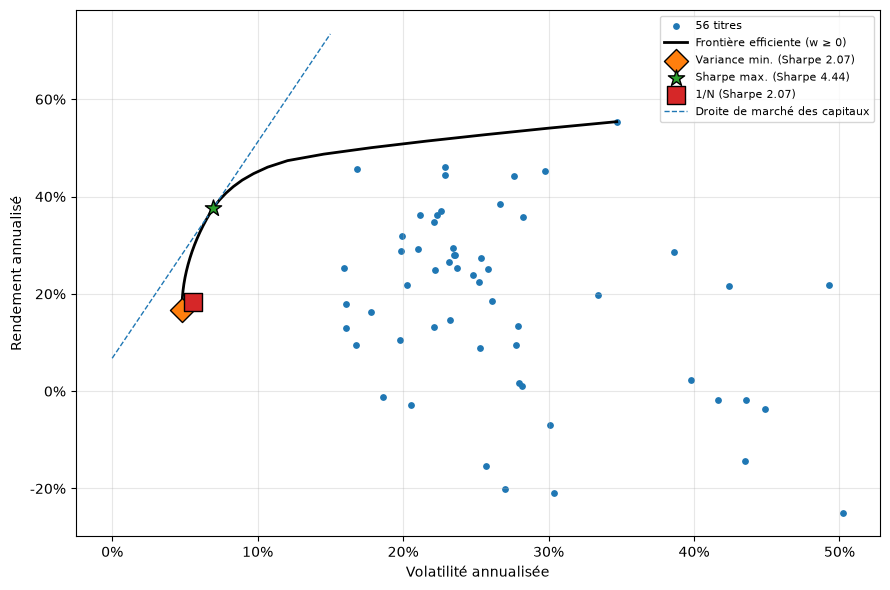

In [7]:
from scipy import optimize
A, n_t = Sigma.values, len(Sigma)

# 1. Variance minimale SANS vente à découvert : min wᵀΣw  avec  Σw = 1  et  w ≥ 0
def min_var(cible=None):
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    if cible is not None:                                   # pour la frontière
        cons.append({"type": "eq", "fun": lambda w: w @ mu_a.values - cible})
    res = optimize.minimize(lambda w: w @ A @ w, np.full(n_t, 1/n_t), jac=lambda w: 2*A@w,
                            bounds=[(0, 1)]*n_t, constraints=cons, method="SLSQP",
                            options={"ftol": 1e-12, "maxiter": 1000})
    w = np.clip(res.x, 0, None); return pd.Series(w / w.sum(), index=Sigma.index)

w_gmv_lo = min_var()

# 2. Sharpe maximal SANS vente à découvert (reformulation convexe) :
#    min yᵀΣy  avec (μ − rf)ᵀy = 1 et y ≥ 0, puis w = y / Σy
e = (mu_a - RF).values
res = optimize.minimize(lambda y: y @ A @ y, np.full(n_t, 1/(n_t*e.max())), jac=lambda y: 2*A@y,
                        bounds=[(0, None)]*n_t,
                        constraints=[{"type": "eq", "fun": lambda y: y @ e - 1}],
                        method="SLSQP", options={"ftol": 1e-14, "maxiter": 2000})
w_ms = pd.Series(np.clip(res.x, 0, None), index=Sigma.index); w_ms /= w_ms.sum()

# 3. Portefeuille équipondéré 1/N, pour comparer
w_eq = pd.Series(1/n_t, index=Sigma.index)

for nom, w in [("Variance min. (w ≥ 0)", w_gmv_lo), ("Sharpe max. (w ≥ 0)", w_ms), ("1/N", w_eq)]:
    r, v, sh = perf(w)
    print(f"{nom:24s} rendement {r:6.1%}  volatilité {v:5.1%}  Sharpe {sh:5.2f}  titres > 1 % : {(w > 0.01).sum()}")
print("\nSharpe max., composition :\n", w_ms[w_ms > 0.01].sort_values(ascending=False).round(3))

# 4. Frontière efficiente : pour chaque rendement visé, le portefeuille de risque minimal
cibles = np.linspace(perf(w_gmv_lo)[0], mu_a.max(), 30)
front = pd.DataFrame([perf(min_var(c)) for c in cibles], columns=["rendement", "volatilite", "sharpe"])

# 5. Graphique
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(F["volatilite_annualisee"], mu_a, s=15, label="56 titres")
ax.plot(front["volatilite"], front["rendement"], "k-", lw=2, label="Frontière efficiente (w ≥ 0)")
for nom, w, m in [("Variance min.", w_gmv_lo, "D"), ("Sharpe max.", w_ms, "*"), ("1/N", w_eq, "s")]:
    r, v, sh = perf(w); ax.scatter(v, r, marker=m, s=150, edgecolor="k", zorder=5, label=f"{nom} (Sharpe {sh:.2f})")
x = np.linspace(0, 0.15, 10); ax.plot(x, RF + perf(w_ms)[2]*x, "--", lw=1, label="Droite de marché des capitaux")
ax.set_xlabel("Volatilité annualisée"); ax.set_ylabel("Rendement annualisé"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig("resultats/frontiere_efficiente.png", dpi=150); plt.show()

w_gmv_lo.to_csv("resultats/poids_variance_min.csv"); w_ms.to_csv("resultats/poids_sharpe_max.csv")
front.to_csv("resultats/frontiere.csv", index=False)

In [8]:
# Autocorrélation : un rendement d'aujourd'hui "prédit-il" celui de demain ?
print(f"Autocorrélation d'ordre 1 du Tunindex : {M.autocorr(1):.2f} (0 attendu sur un marché efficient)")

# Même calcul de risque avec des rendements hebdomadaires
Rw, Mw = R.resample("W-FRI").sum(), M.resample("W-FRI").sum()
Sigma_w = Rw.cov() * 52
print(f"Volatilité du Tunindex : {M.std()*np.sqrt(252):.1%} (journalière × √252) contre {Mw.std()*np.sqrt(52):.1%} (hebdomadaire × √52)")

r_ms = float(w_ms @ mu_a)
print(f"Sharpe max. : {perf(w_ms)[2]:.2f} avec la covariance journalière, "
      f"{(r_ms - RF) / np.sqrt(w_ms @ Sigma_w.values @ w_ms):.2f} avec la covariance hebdomadaire")

Autocorrélation d'ordre 1 du Tunindex : 0.29 (0 attendu sur un marché efficient)
Volatilité du Tunindex : 7.6% (journalière × √252) contre 9.9% (hebdomadaire × √52)
Sharpe max. : 4.44 avec la covariance journalière, 3.40 avec la covariance hebdomadaire


    inertie  silhouette  calinski_harabasz
k                                         
2    55.265       0.495             55.437
3    36.198       0.426             55.494
4    27.272       0.371             53.852
5    20.911       0.381             55.541
6    16.560       0.388             57.632
7    13.248       0.417             60.875
8    11.214       0.409             61.631
9     9.493       0.401             63.439
10    8.259       0.396             64.200


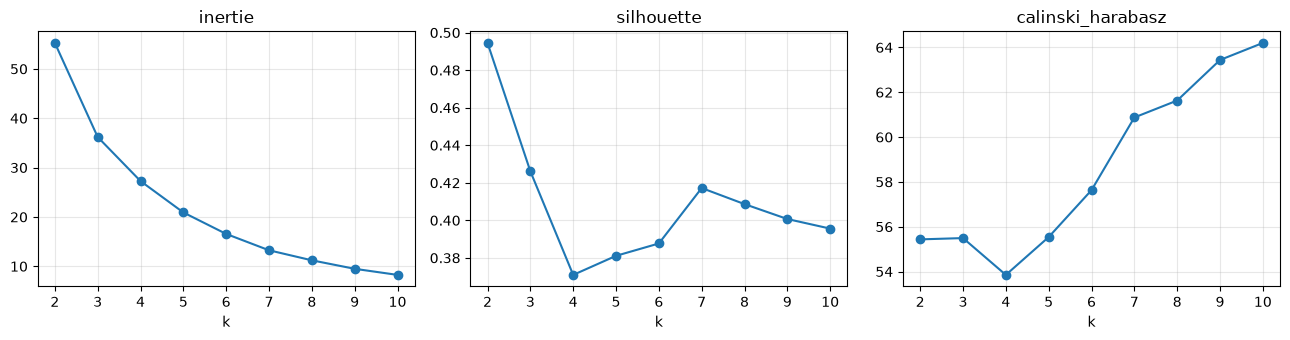

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# 1. Les 2 variables, standardisées (moyenne 0, écart-type 1)
X2 = F[["rendement_annualise", "volatilite_annualisee"]]
Z2 = StandardScaler().fit_transform(X2)

# 2. On essaie k = 2 à 10 et on calcule les 3 critères
res = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=42).fit(Z2)
    res.append({"k": k, "inertie": km.inertia_,
                "silhouette": silhouette_score(Z2, km.labels_),
                "calinski_harabasz": calinski_harabasz_score(Z2, km.labels_)})
choix = pd.DataFrame(res).set_index("k")
print(choix.round(3))

# 3. Les 3 courbes
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, c in zip(axes, choix.columns):
    ax.plot(choix.index, choix[c], "o-"); ax.set_title(c); ax.set_xlabel("k"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("resultats/choix_k_plan.png", dpi=150); plt.show()

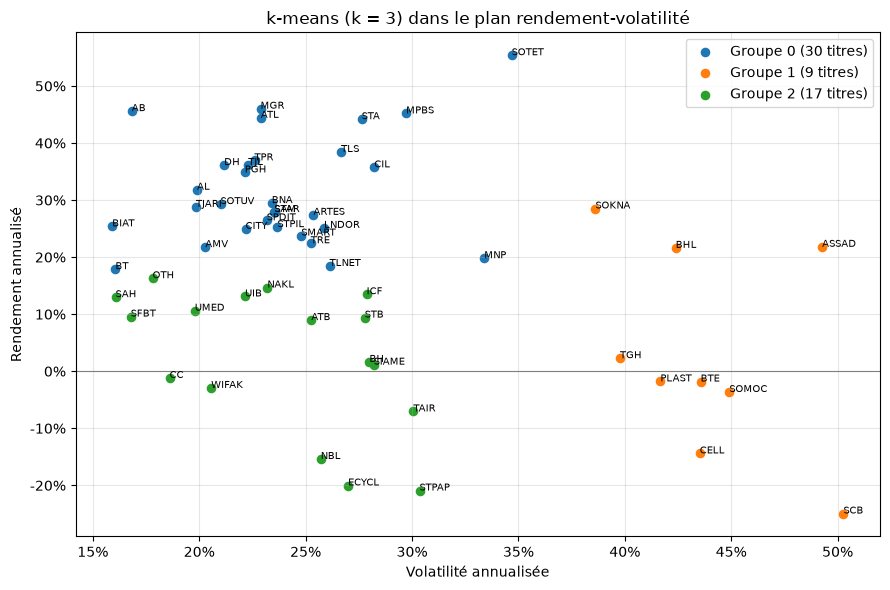

              rendement_annualise  volatilite_annualisee  skewness  kurtosis  \
cluster_plan                                                                   
0                           0.318                  0.237     0.742     6.786   
1                           0.031                  0.438    -0.021    12.198   
2                           0.026                  0.238     0.271     5.577   

              VaR_95   beta  
cluster_plan                 
0              0.021  0.644  
1              0.042  0.149  
2              0.022  0.473  

Groupe 0 : AB, AL, AMV, ARTES, ATL, BIAT, BNA, BT, CIL, CITY, DH, LNDOR, MGR, MNP, MPBS, PGH, SAM, SMART, SOTET, SOTUV, SPDIT, STA, STAR, STPIL, TJARI, TJL, TLNET, TLS, TPR, TRE

Groupe 1 : ASSAD, BHL, BTE, CELL, PLAST, SCB, SOKNA, SOMOC, TGH

Groupe 2 : ATB, BH, CC, ECYCL, ICF, NAKL, NBL, OTH, SAH, SFBT, SIAME, STB, STPAP, TAIR, UIB, UMED, WIFAK


In [10]:
K = 3
km2 = KMeans(n_clusters=K, init="k-means++", n_init=50, random_state=42).fit(Z2)
F["cluster_plan"] = km2.labels_

# 1. Graphique des groupes
fig, ax = plt.subplots(figsize=(9, 6))
for c in range(K):
    g = F[F["cluster_plan"] == c]
    ax.scatter(g["volatilite_annualisee"], g["rendement_annualise"], s=35, label=f"Groupe {c} ({len(g)} titres)")
for t in F.index:
    ax.annotate(t, (F.loc[t, "volatilite_annualisee"], F.loc[t, "rendement_annualise"]), fontsize=7)
ax.axhline(0, color="gray", lw=0.8); ax.legend(); ax.grid(alpha=0.3)
ax.set_xlabel("Volatilité annualisée"); ax.set_ylabel("Rendement annualisé")
ax.set_title("k-means (k = 3) dans le plan rendement-volatilité")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig("resultats/kmeans_plan_k3.png", dpi=150); plt.show()

# 2. Portrait moyen de chaque groupe
cols = ["rendement_annualise", "volatilite_annualisee", "skewness", "kurtosis", "VaR_95", "beta"]
print(F.groupby("cluster_plan")[cols].mean().round(3))

# 3. Liste des titres de chaque groupe
for c in range(K):
    print(f"\nGroupe {c} :", ", ".join(sorted(F.index[F["cluster_plan"] == c])))
    

In [11]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

feat = ["rendement_annualise", "volatilite_annualisee", "skewness", "kurtosis", "VaR_95", "CVaR_95", "beta"]
Z7 = StandardScaler().fit_transform(F[feat])          # 7 indicateurs standardisés

# 1. PCA : combien d'information porte chaque composante ?
pca = PCA().fit(Z7)
print("Variance expliquée :", pca.explained_variance_ratio_.round(3))
print("Cumulée            :", pca.explained_variance_ratio_.cumsum().round(3))
print(pd.DataFrame(pca.components_[:3].T, index=feat, columns=["CP1", "CP2", "CP3"]).round(2))

n_cp = int(np.argmax(pca.explained_variance_ratio_.cumsum() >= 0.80) + 1)   # au moins 80 % de l'information
Zp = PCA(n_components=n_cp).fit_transform(Z7)
print("Composantes retenues :", n_cp)

# 2. Choix de k dans les deux espaces
def criteres(Z):
    out = []
    for k in range(2, 11):
        km = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=42).fit(Z)
        out.append({"k": k, "inertie": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                    "calinski_harabasz": calinski_harabasz_score(Z, km.labels_)})
    return pd.DataFrame(out).set_index("k")

c7, cp = criteres(Z7), criteres(Zp)
print("\nSans PCA (7 indicateurs) :\n", c7.round(3))
print(f"\nAvec PCA ({n_cp} composantes) :\n", cp.round(3))

Variance expliquée : [0.57  0.163 0.133 0.082 0.046 0.004 0.002]
Cumulée            : [0.57  0.733 0.866 0.948 0.994 0.998 1.   ]
                        CP1   CP2   CP3
rendement_annualise   -0.31  0.19  0.66
volatilite_annualisee  0.46  0.14  0.35
skewness              -0.31  0.61  0.21
kurtosis               0.19  0.75 -0.39
VaR_95                 0.46 -0.03  0.36
CVaR_95                0.48  0.08  0.21
beta                  -0.34 -0.05  0.25
Composantes retenues : 3

Sans PCA (7 indicateurs) :
     inertie  silhouette  calinski_harabasz
k                                         
2   226.118       0.453             39.615
3   191.401       0.229             27.773
4   162.463       0.239             24.489
5   134.927       0.259             24.292
6   111.913       0.276             25.027
7    98.250       0.272             24.417
8    89.009       0.243             23.342
9    80.790       0.242             22.631
10   72.657       0.247             22.464

Avec PCA (3 composante

In [12]:
# 1. Le tableau "avec PCA" en entier
print(f"Avec PCA ({n_cp} composantes) :\n", cp.round(3).to_string())

# 2. Taille des groupes pour k = 2, 3 et 4, sans et avec PCA
for nom, Z in [("Sans PCA", Z7), ("Avec PCA", Zp)]:
    for k in [2, 3, 4]:
        lab = KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=42).fit_predict(Z)
        tailles = pd.Series(lab).value_counts().sort_index().tolist()
        petit = pd.Series(lab).value_counts().idxmin()
        print(f"{nom}, k={k} : tailles {tailles} | plus petit groupe : {', '.join(F.index[lab == petit])}")

# 3. Le titre à la kurtosis la plus forte
print("\nKurtosis la plus élevée :\n", F["kurtosis"].sort_values(ascending=False).head(3).round(1))

Avec PCA (3 composantes) :
     inertie  silhouette  calinski_harabasz
k                                         
2   173.817       0.514             51.423
3   140.691       0.339             37.417
4   114.732       0.361             33.933
5    90.613       0.383             34.998
6    68.799       0.345             39.324
7    59.293       0.342             38.572
8    51.985       0.325             37.904
9    43.779       0.358             39.663
10   37.378       0.357             41.291
Sans PCA, k=2 : tailles [43, 13] | plus petit groupe : ASSAD, BHL, BTE, CELL, MNP, NBL, PLAST, SCB, SOKNA, SOMOC, STPAP, TAIR, TGH
Sans PCA, k=3 : tailles [12, 17, 27] | plus petit groupe : ASSAD, BHL, BTE, CELL, MNP, NBL, PLAST, SCB, SOKNA, SOMOC, STPAP, TGH
Sans PCA, k=4 : tailles [7, 17, 27, 5] | plus petit groupe : CELL, NBL, SCB, SOMOC, STPAP
Avec PCA, k=2 : tailles [43, 13] | plus petit groupe : ASSAD, BHL, BTE, CELL, MNP, NBL, PLAST, SCB, SOKNA, SOMOC, STPAP, TAIR, TGH
Avec PCA, k=3 : ta

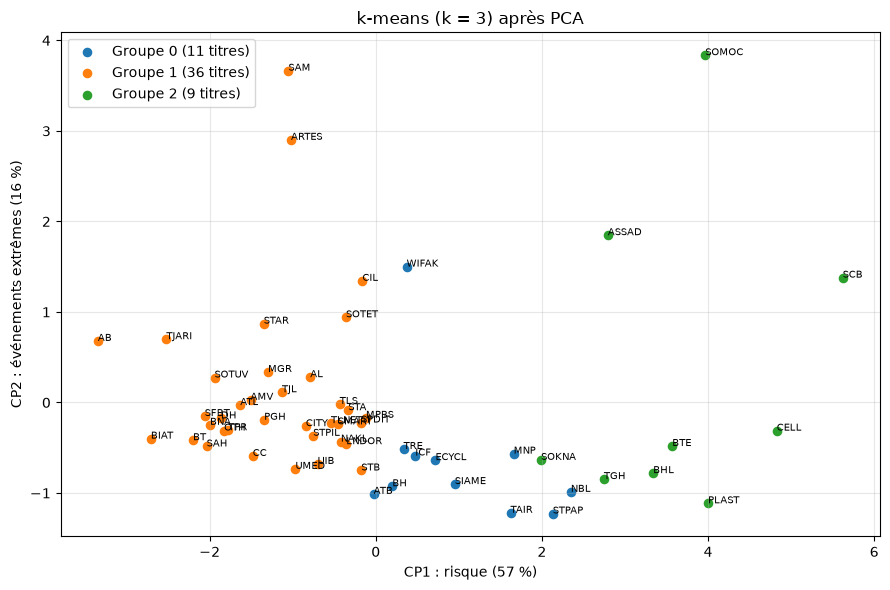

                rendement_annualise  volatilite_annualisee  skewness  \
cluster_pca_k3                                                         
0                             0.001                  0.274    -0.023   
1                             0.277                  0.226     0.753   
2                             0.031                  0.438    -0.021   

                kurtosis  VaR_95  CVaR_95   beta  
cluster_pca_k3                                    
0                  6.989   0.027    0.040  0.324  
1                  6.153   0.019    0.030  0.661  
2                 12.198   0.042    0.062  0.149  

Groupe 0 : ATB, BH, ECYCL, ICF, MNP, NBL, SIAME, STPAP, TAIR, TRE, WIFAK

Groupe 1 : AB, AL, AMV, ARTES, ATL, BIAT, BNA, BT, CC, CIL, CITY, DH, LNDOR, MGR, MPBS, NAKL, OTH, PGH, SAH, SAM, SFBT, SMART, SOTET, SOTUV, SPDIT, STA, STAR, STB, STPIL, TJARI, TJL, TLNET, TLS, TPR, UIB, UMED

Groupe 2 : ASSAD, BHL, BTE, CELL, PLAST, SCB, SOKNA, SOMOC, TGH

ARI plan (k=3) vs PCA (k=3)     :

In [13]:
# 1. Partitions finales
lab_k2  = KMeans(n_clusters=2, init="k-means++", n_init=50, random_state=42).fit_predict(Zp)
lab_k3  = KMeans(n_clusters=3, init="k-means++", n_init=50, random_state=42).fit_predict(Zp)
lab_7k3 = KMeans(n_clusters=3, init="k-means++", n_init=50, random_state=42).fit_predict(Z7)
F["cluster_pca_k2"], F["cluster_pca_k3"] = lab_k2, lab_k3

# 2. Graphique dans le plan des 2 premières composantes (k = 3)
fig, ax = plt.subplots(figsize=(9, 6))
for c in range(3):
    m = lab_k3 == c
    ax.scatter(Zp[m, 0], Zp[m, 1], s=35, label=f"Groupe {c} ({m.sum()} titres)")
for i, t in enumerate(F.index):
    ax.annotate(t, (Zp[i, 0], Zp[i, 1]), fontsize=7)
ax.set_xlabel("CP1 : risque (57 %)"); ax.set_ylabel("CP2 : événements extrêmes (16 %)")
ax.set_title("k-means (k = 3) après PCA"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("resultats/kmeans_pca_k3.png", dpi=150); plt.show()

# 3. Portrait de chaque groupe (k = 3, avec PCA)
print(F.groupby("cluster_pca_k3")[feat].mean().round(3))
for c in range(3):
    print(f"\nGroupe {c} :", ", ".join(sorted(F.index[lab_k3 == c])))

# 4. Les partitions se ressemblent-elles ? (indice de Rand ajusté : 1 = identiques, 0 = hasard)
print("\nARI plan (k=3) vs PCA (k=3)     :", round(adjusted_rand_score(F["cluster_plan"], lab_k3), 2))
print("ARI 7 indicateurs vs PCA (k=3)  :", round(adjusted_rand_score(lab_7k3, lab_k3), 2))
F.to_csv("resultats/features_et_clusters.csv")

ticker
SOMOC    0.651
ASSAD    0.627
NBL      0.622
SCB      0.619
WIFAK    0.603
SAM      0.595
SOTET    0.559
ARTES    0.554
PLAST    0.541
CELL     0.539
STPAP    0.535
AB       0.533
Name: score_IF, dtype: float64


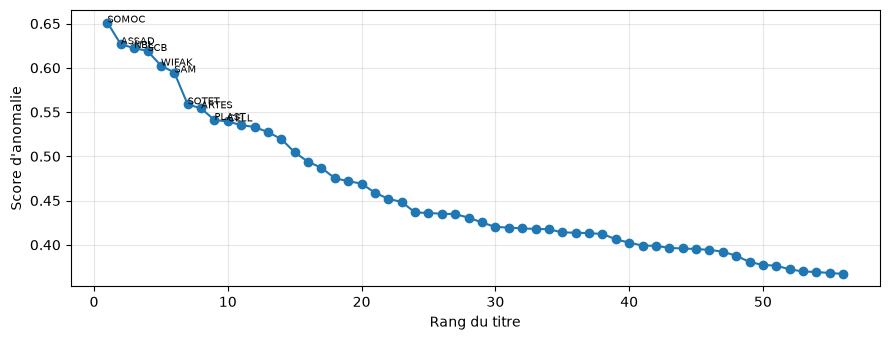


Titres les plus loin du centre de leur groupe (k-means) :
 ticker
SOMOC    3.82
SAM      3.66
ARTES    2.82
SCB      2.71
WIFAK    2.68
NBL      2.57
SOTET    2.35
SOKNA    2.32
ASSAD    2.28
AB       2.24
Name: dist_kmeans, dtype: float64


In [14]:
from sklearn.ensemble import IsolationForest

# 1. Score d'anomalie de chaque titre (plus il est grand, plus le titre est isolé)
iso = IsolationForest(n_estimators=1000, random_state=42).fit(Zp)
F["score_IF"] = -iso.score_samples(Zp)
s = F["score_IF"].sort_values(ascending=False)
print(s.head(12).round(3))

# 2. Scores triés : on cherche la "cassure" pour justifier le taux de contamination
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(range(1, len(s) + 1), s.values, "o-")
for i, t in enumerate(s.index[:10]):
    ax.annotate(t, (i + 1, s.values[i]), fontsize=7)
ax.set_xlabel("Rang du titre"); ax.set_ylabel("Score d'anomalie"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("resultats/scores_isolation_forest.png", dpi=150); plt.show()

# 3. Côté k-means : distance de chaque titre au centre de son groupe
km3 = KMeans(n_clusters=3, init="k-means++", n_init=50, random_state=42).fit(Zp)
F["dist_kmeans"] = np.linalg.norm(Zp - km3.cluster_centers_[km3.labels_], axis=1)
print("\nTitres les plus loin du centre de leur groupe (k-means) :\n",
      F["dist_kmeans"].sort_values(ascending=False).head(10).round(2))

In [15]:
# 1. Isolation Forest avec la contamination justifiée par la cassure
CONT = 6 / 56
iso_f = IsolationForest(n_estimators=1000, contamination=CONT, random_state=42).fit(Zp)
F["anomalie_IF"] = iso_f.predict(Zp) == -1

# 2. Anomalies côté k-means : les 6 titres les plus loin de leur centre
F["anomalie_kmeans"] = F["dist_kmeans"].rank(ascending=False) <= 6

# 3. Comparaison
print("Isolation Forest :", sorted(F.index[F["anomalie_IF"]]))
print("k-means          :", sorted(F.index[F["anomalie_kmeans"]]))
print("Communs          :", sorted(F.index[F["anomalie_IF"] & F["anomalie_kmeans"]]))
print("Anomalies dans le groupe spéculatif :",
      sorted(F.index[F["anomalie_IF"] & (F["cluster_pca_k3"] == 2)]))

F.to_csv("resultats/features_clusters_anomalies.csv")
print("\nFichier final enregistré.")

Isolation Forest : ['ASSAD', 'NBL', 'SAM', 'SCB', 'SOMOC', 'WIFAK']
k-means          : ['ARTES', 'NBL', 'SAM', 'SCB', 'SOMOC', 'WIFAK']
Communs          : ['NBL', 'SAM', 'SCB', 'SOMOC', 'WIFAK']
Anomalies dans le groupe spéculatif : ['ASSAD', 'SCB', 'SOMOC']

Fichier final enregistré.
